In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/crypto/crypto.csv


# **Python Practice: Stationarity and Autocorrelation**

In this practice, we check two problems with Bitcoin (BTC) prices:
1. Are prices stationary?
2. Are prices autocorrelated?

Then we take the first difference (returns) and check again.

## **About the Data**

The file `btc.csv` contains daily closing prices of Bitcoin.

| Column | What it means |
|---|---|
| Date | Day ([start date] – [end date]) |
| BTC | Bitcoin price, in US dollars |

There are [...] daily observations. Unlike shares, Bitcoin trades **every day**, including weekends and holidays.

## **Step 1: Import the Libraries**

Libraries are ready-made tools. We import them once at the start.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings("ignore")

## **Step 2: Upload the Data**

Copy the file path from the right-hand sidebar in Kaggle and paste it inside the quotation marks.

In [18]:
df = pd.read_csv("/kaggle/input/datasets/robinaz/crypto/crypto.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.set_index("Date")
df.head()

,BTC
Date,
2015-01-01,201.7391
2015-01-02,205.5674
2015-01-03,183.4140
2015-01-04,172.8799
2015-01-05,179.9004


## **Step 3: Check Stationarity of Prices – Plot**

Look at the plot. Does each price return to the same level, or does it wander away?

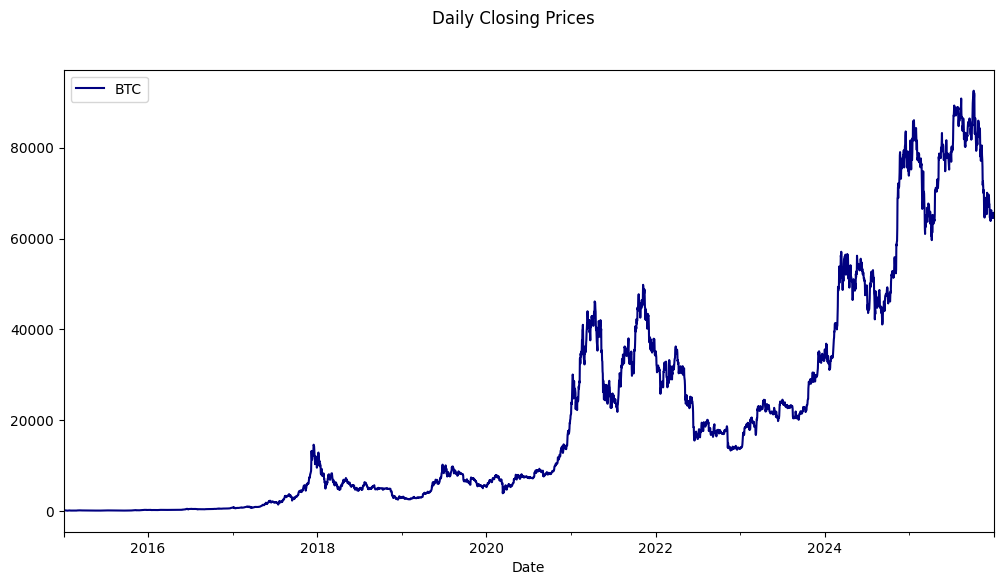

In [19]:
df.plot(subplots=True, figsize=(12, 6), title="Daily Closing Prices", color=["navy", "darkred"])
plt.show()

**Interpretation:** The BTC price rises and falls in big waves and does not return to a fixed level. The average is not constant, so the price looks **non-stationary**. We now confirm this with a test.

## **Step 4: Check Stationarity of Prices – ADF Test (Unit Root Test)**

The ADF test checks whether the price has a unit root. A unit root means the price is non-stationary.

- H₀: The series has a unit root (non-stationary).
- H₁: The series is stationary.
- If p-value < 0.05 → reject H₀ → stationary.

In [20]:
print("BTC price ADF p-value:", round(adfuller(df["BTC"])[1], 4))

BTC price ADF p-value: 0.7841


**Interpretation:** The p-value is well above 0.05, so we cannot reject H₀. The BTC price has a unit root and is **non-stationary**. This matches what we saw in the plot.

## **Step 5: Check Autocorrelation of Prices – ACF and PACF Plots**

- The **ACF** (autocorrelation function) shows the correlation between today's price and the price *s* days ago. It includes the indirect effect passed through the days in between.
- The **PACF** (partial autocorrelation function) shows the **direct** link between today's price and the price *s* days ago, after removing the effect of the days in between.

Bars outside the blue band are significant.

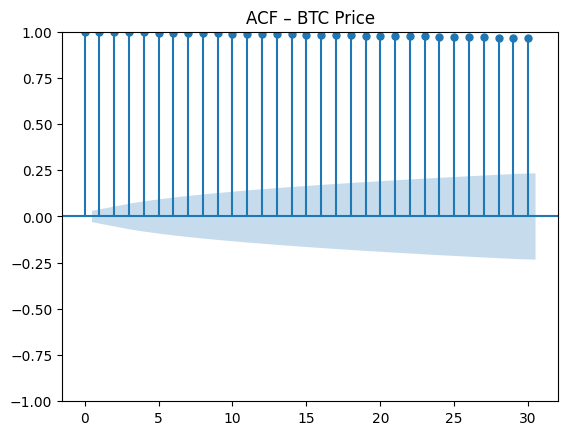

In [21]:
plot_acf(df["BTC"], lags=30, title="ACF – BTC Price")
plt.show()

**Interpretation:** All the bars are close to 1 and far outside the blue band. They fade very slowly. Today's price is almost the same as yesterday's price, so the price is **strongly autocorrelated**.

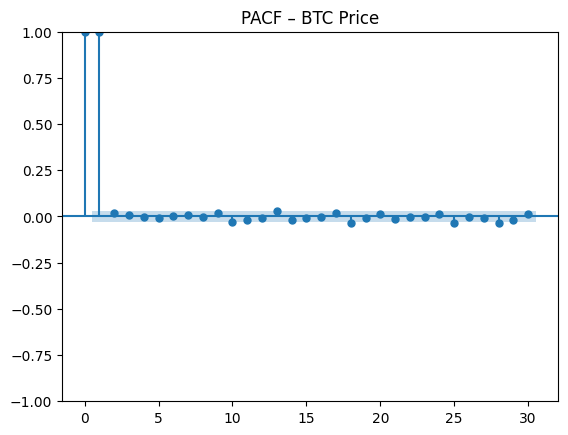

In [22]:
plot_pacf(df["BTC"], lags=30, title="PACF – BTC Price")
plt.show()

**Interpretation:** Only the lag 1 bar is close to 1. All the other bars are near zero. Today's price depends directly on yesterday's price only, which is a sign of a unit root (non-stationary).

## **Step 6: Check Autocorrelation of Prices – Ljung–Box Test**

The Ljung–Box test checks the first 10 lags together.

- H₀: There is no autocorrelation.
- H₁: There is autocorrelation.
- If p-value < 0.05 → reject H₀ → autocorrelated.

In [23]:
print("BTC price Ljung-Box p-value:", round(acorr_ljungbox(df["BTC"], lags=[10])["lb_pvalue"].iloc[0], 4))

BTC price Ljung-Box p-value: 0.0


**Interpretation:** The p-value is 0.0, which is below 0.05, so we reject H₀. The price is **heavily autocorrelated**. This confirms the ACF plot.

So the price has two problems: it is non-stationary and autocorrelated. Next, we fix this by taking the first difference.

## **Step 7: Take the First Difference (Returns)**

The first difference of the log price is the log return: today's log price minus yesterday's log price. We multiply by 100 to get returns in %. The first row is removed because it has no "yesterday".

In [24]:
returns = np.log(df["BTC"]).diff().dropna() * 100

In [25]:
returns.head()

Date
2015-01-02     1.879868
2015-01-03   -11.402807
2015-01-04    -5.914876
2015-01-05     3.980623
2015-01-06     4.975838
Name: BTC, dtype: float64

## **Step 8: Check Stationarity of Returns – Plot**

Do the returns move around a fixed level?

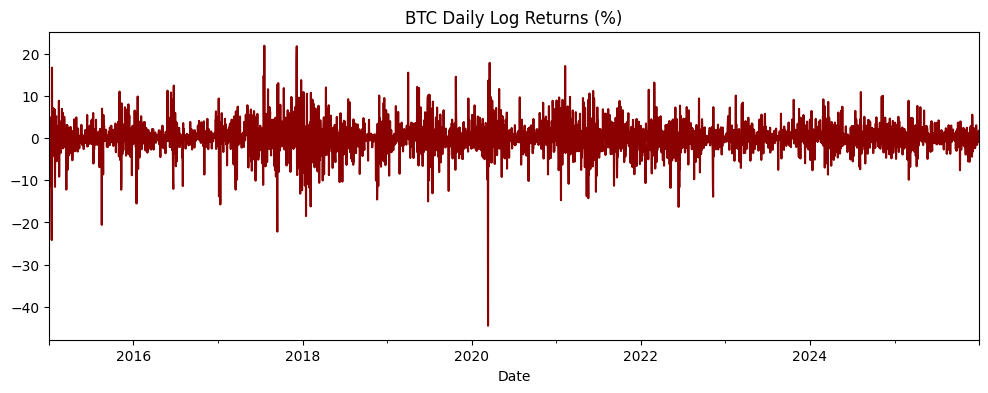

In [26]:
returns.plot(figsize=(12, 4), title="BTC Daily Log Returns (%)", color="darkred")
plt.show()

**Interpretation:** Returns move up and down around zero and keep coming back to it. They look **stationary**. Notice that BTC returns are much bigger than share returns: daily moves of 10% or more are not unusual.

## **Step 9: Check Stationarity of Returns – ADF Test (Unit Root Test)**

- H₀: The series has a unit root (non-stationary).
- H₁: The series is stationary.
- If p-value < 0.05 → reject H₀ → stationary.

In [27]:
print("BTC returns ADF p-value:", round(adfuller(returns)[1], 4))

BTC returns ADF p-value: 0.0


**Interpretation:** The p-value is 0.0, which is below 0.05, so we reject H₀. Returns have no unit root and are **stationary**. Taking the first difference has fixed Problem 1.

## **Step 10: Check Autocorrelation of Returns – ACF Plot**

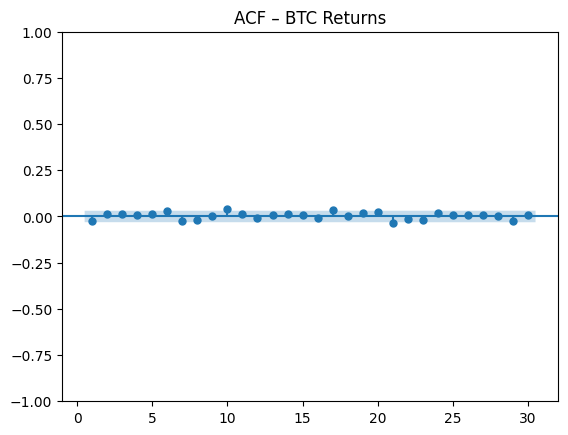

In [28]:
plot_acf(returns, lags=30, zero=False, title="ACF – BTC Returns")
plt.show()

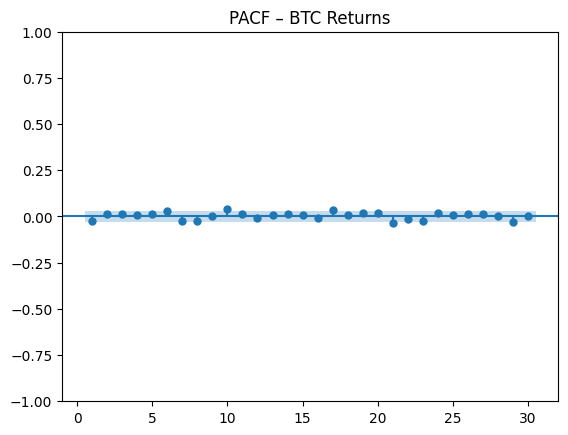

In [29]:
plot_pacf(returns, lags=30, zero=False, title="PACF – BTC Returns")
plt.show()

**Interpretation:** The bars are now very small, close to zero. A few bars may go just outside the blue band, but they are tiny compared with the price ACF.

## **Step 11: Check Autocorrelation of Returns – Ljung–Box Test**

- H₀: There is no autocorrelation.
- H₁: There is autocorrelation.
- If p-value < 0.05 → reject H₀ → autocorrelated.

In [30]:
print("BTC returns Ljung-Box p-value:", round(acorr_ljungbox(returns, lags=[10])["lb_pvalue"].iloc[0], 4))

BTC returns Ljung-Box p-value: 0.055


**Interpretation:** The p-value is 0.055, which is just above 0.05, so we **cannot reject H₀**. BTC returns have **no significant autocorrelation** at the 5% level. Because 0.055 is very close to 0.05, there may be a **very weak** pattern left, but it is too small to be significant.

So taking the first difference has fixed **both** problems: returns are stationary and have (almost) no autocorrelation. This fits the efficient markets idea: yesterday's BTC return tells us very little about today's return.

Next week, we still build MA, AR and ARMA models to test this formally, model by model.

| | Stationary? (Plot + ADF) | Autocorrelated? (ACF + Ljung–Box) |
|---|---|---|
| BTC price | No, it has a unit root | Yes, strongly (bars near 1, p = 0.00) |
| BTC returns (first difference) | Yes, no unit root (p = 0.00) | No, not significant (p = 0.055) |